# 04 · Error analysis

Where each system fails, sliced by orthography, English mixing, length and emoji.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)

In [2]:
import subprocess
out = subprocess.run([sys.executable, str(ROOT/'scripts/run_error_analysis.py')], capture_output=True, text=True, cwd=ROOT)
print(out.stdout[-1500:], out.stderr[-800:])

ength           6-12 485             0.1711                 0.5673                     0.0969                 0.2416                     0.8598         0.3404             0.5897             0.3397                 0.5278             0.3400                 0.5113
     length            >12 162             0.0617                 0.6227                     0.0988                 0.2531                     0.7593         0.2982             0.5370             0.3843                 0.4444             0.3618                 0.4198
      emoji      has emoji 411             0.1582                 0.5619                     0.1363                 0.3619                     0.6959         0.4337             0.4866             0.3796                 0.4526             0.3696                 0.4769
      emoji       no emoji 538             0.1506                 0.6140                     0.1152                 0.1289                     0.9535         0.2395             0.5948             0.3633

In [3]:
pd.read_csv(ROOT/'reports/metrics/slices.csv')

,dimension,slice,n,gold_neutral_rate,tfidf_logreg_macro_f1,tfidf_logreg_pred_neutral,english_only_macro_f1,english_only_pred_neutral,xlmt_macro_f1,xlmt_pred_neutral,nllb_twi_macro_f1,nllb_twi_pred_neutral,nllb_aka_macro_f1,nllb_aka_pred_neutral
0,orthography,neither,354,0.1864,0.6008,0.1384,0.2628,0.8475,0.3853,0.4181,0.3943,0.5395,0.4172,0.5311
1,orthography,uses ɛ/ɔ,215,0.0930,0.5683,0.1349,0.1701,0.8837,0.2642,0.5860,0.3657,0.4651,0.3889,0.4651
2,orthography,writes 3 for ɛ,380,0.1579,0.5913,0.1053,0.2650,0.8132,0.3257,0.6474,0.3449,0.5342,0.2945,0.5289
3,english_mix,none,651,0.1567,0.6046,0.1275,0.2236,0.8725,0.3241,0.5591,0.3944,0.4977,0.3804,0.5023
4,english_mix,1-25%,272,0.1434,0.5553,0.1103,0.2689,0.7757,0.3508,0.5331,0.3103,0.5735,0.3226,0.5551
5,english_mix,>25%,26,0.1923,0.6426,0.1923,0.3889,0.7692,0.4917,0.4231,0.4614,0.5385,0.4573,0.4231
6,length,<=5 tokens,302,0.1755,0.5966,0.1821,0.2242,0.8576,0.3442,0.4868,0.4048,0.5497,0.3971,0.5728
7,length,6-12,485,0.1711,0.5673,0.0969,0.2416,0.8598,0.3404,0.5897,0.3397,0.5278,0.3400,0.5113
8,length,>12,162,0.0617,0.6227,0.0988,0.2531,0.7593,0.2982,0.5370,0.3843,0.4444,0.3618,0.4198
9,emoji,has emoji,411,0.1582,0.5619,0.1363,0.3619,0.6959,0.4337,0.4866,0.3796,0.4526,0.3696,0.4769


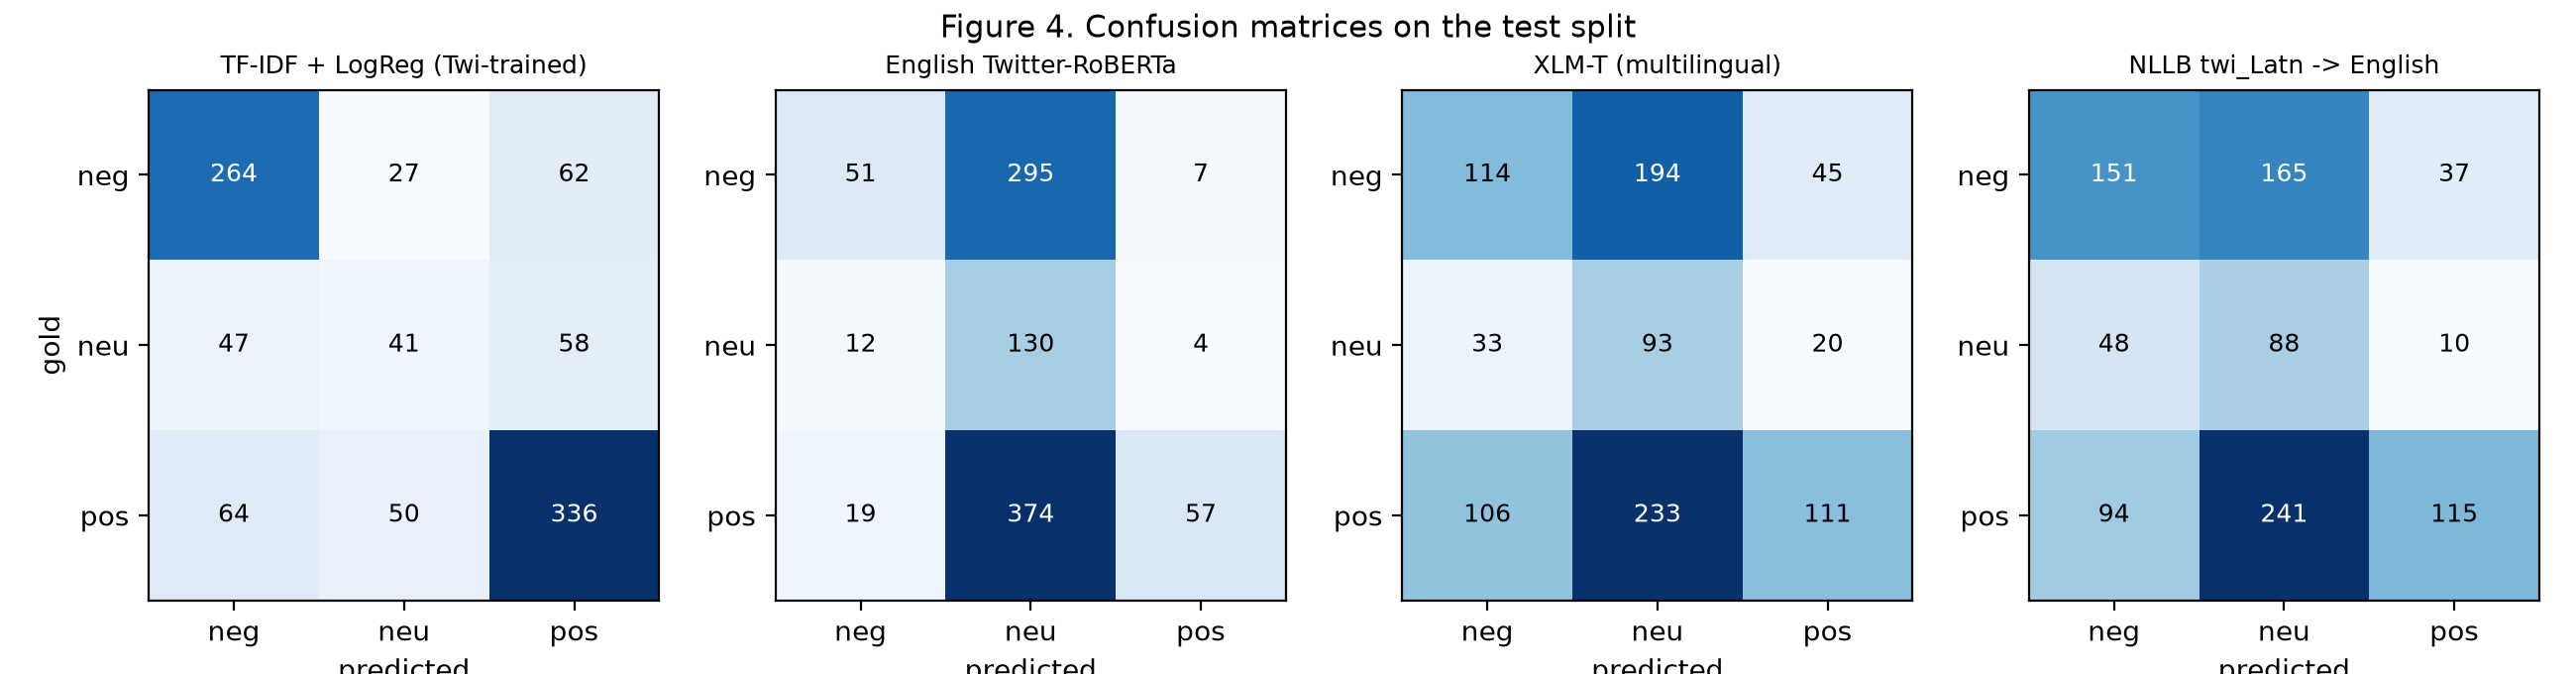

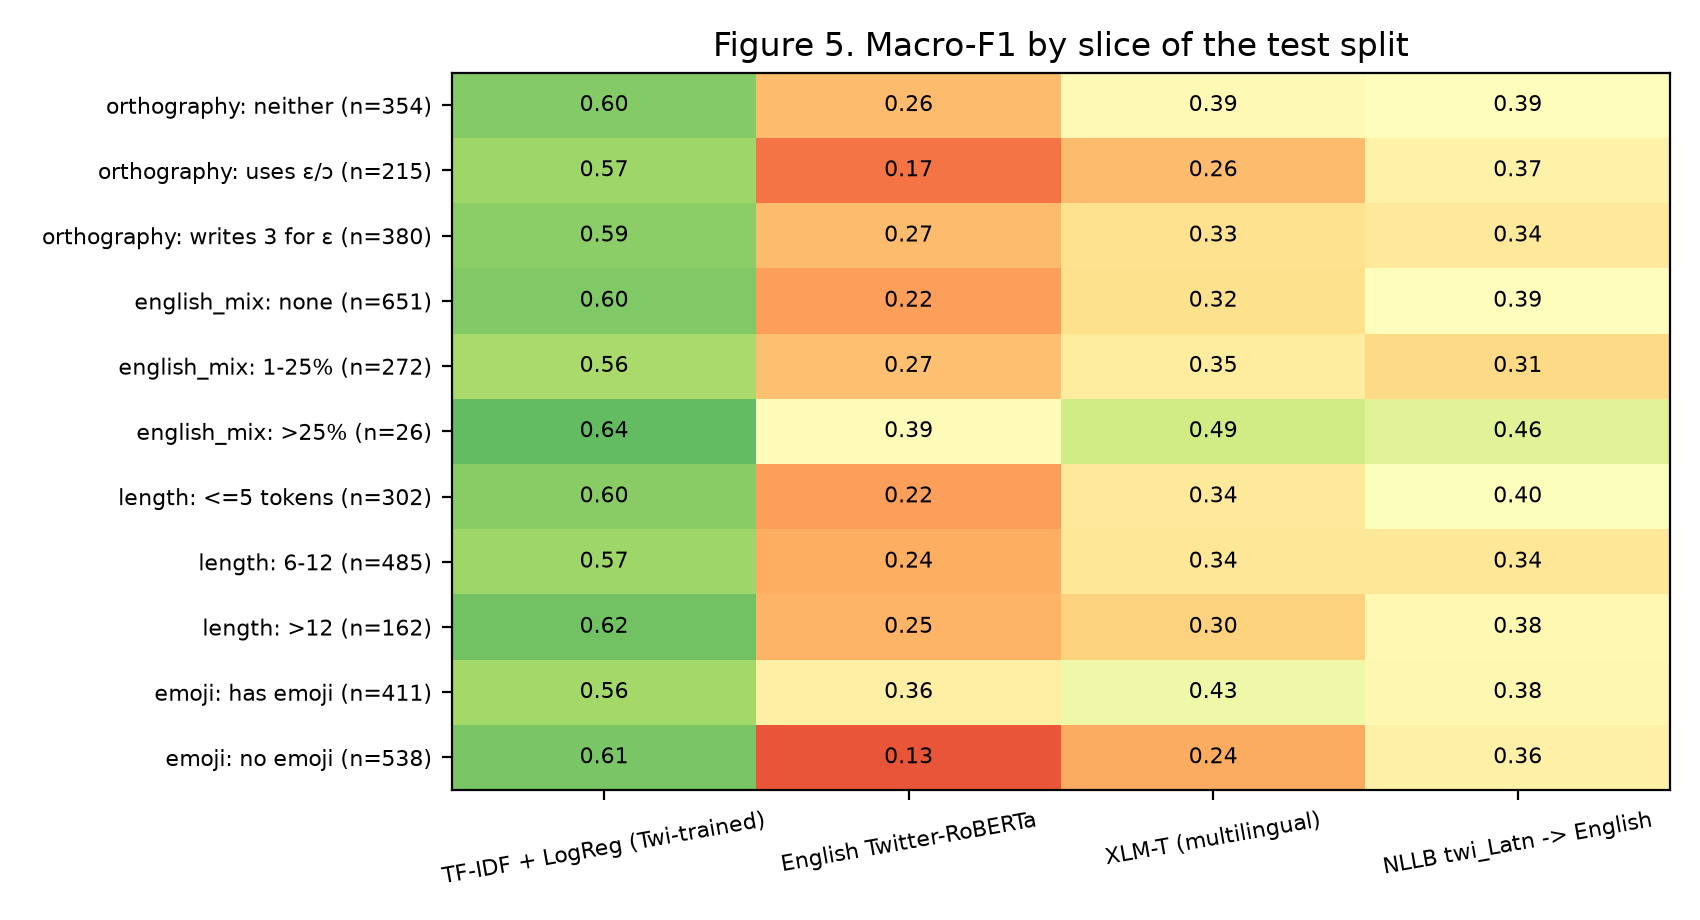

In [4]:
display(Image(str(ROOT/'reports/figures/fig4_confusion.png'), width=900))
display(Image(str(ROOT/'reports/figures/fig5_slices.png'), width=760))

## Sentiment lost in translation

Gold label positive or negative; NLLB twi_Latn → English → English model says neutral.

In [5]:
pd.read_csv(ROOT/'reports/error_analysis/translation_sentiment_loss_sample.csv', keep_default_na=False)[['text','gold','nllb_twi_english','xlmt','tfidf_logreg']].head(12)

,text,gold,nllb_twi_english,xlmt,tfidf_logreg
0,eei mmaa wɔ world,positive,women in the world,negative,positive
1,herh information wo wiase,positive,herh information your world,positive,positive
2,gyae nsem hunu no na wano ee s nsuo,negative,Let go of the empty things and drink like water,neutral,negative
3,s3 anka social media hype nkoa n3 ma hitz s3 anka obia feature mugeez 😂😂,positive,S3 would have been social media hype slaves n3 for hitz s3 would have been theft featu...,neutral,positive
4,data wɔ wiase o,positive,data in the world,neutral,positive
5,jordan wont kill me eeii wey player this koraa,negative,jordan won't kill me yeah wey player this at all,negative,negative
6,masa t boordi3 5gh nkosua baako 😂😂😂😂😂😂,positive,Masa t boordi3 5gh one egg 😂😂😂😂😂,neutral,positive
7,mo de 3ka b3gu mu so,negative,You can add 3 to the list.,neutral,positive
8,yɛn ka kyerɛ wo agenda da sika pafuuuu so,positive,Tell us your agenda is on a lot of money,neutral,positive
9,black stars this black stars that charlie mu yɛ dede pɛ milo bi nom na yɛn partey wai,positive,black stars this black stars that Charlie's in the noise just drink a mile and our par...,neutral,positive


## Tweets every non-trivial system gets wrong

In [6]:
pd.read_csv(ROOT/'reports/error_analysis/all_systems_wrong_sample.csv', keep_default_na=False)[['text','gold','tfidf_logreg','xlmt','nllb_twi','orthography']].head(12)

,text,gold,tfidf_logreg,xlmt,nllb_twi,orthography
0,na wonnso adein😂😂dein na tema boys ay3 wo,positive,neutral,neutral,negative,writes 3 for ɛ
1,arh eii mey3 kraa ahy3 me 😂,neutral,positive,positive,negative,writes 3 for ɛ
2,menua nti ne korakora nisen,neutral,positive,negative,negative,neither
3,wo brofo sem da fom b3t33😂😂😂💔,positive,negative,negative,negative,writes 3 for ɛ
4,nhoma sua bebree nanso still yɛ de bɔ krɔno,negative,positive,neutral,neutral,uses ɛ/ɔ
5,oracle mu nana agradaa akai,negative,neutral,positive,neutral,neither
6,na fam delete this 😩,neutral,negative,negative,negative,neither
7,otan hunu ara kwa,positive,negative,negative,negative,neither
8,wei y3 de gye ballon dor😂,negative,positive,neutral,neutral,writes 3 for ɛ
9,masa woboa mede3 esweet me papa once said ade3 3y3 d3 wo mmaa ho nti na ahenfo kyeky3 ...,positive,negative,neutral,neutral,writes 3 for ɛ


## Label flips caused only by the source-language code

In [7]:
pd.read_csv(ROOT/'reports/error_analysis/source_code_flips_sample.csv', keep_default_na=False).head(10)

,text,gold,nllb_twi,nllb_twi_english,nllb_aka,nllb_aka_english
0,3ny3 s3 obi koti y3 kitikiti oo ne tw3 n3 so kwasiaaa baaa sei,negative,neutral,3ny3 s3 someone's coat y3 ticket or the tw3 n3 ticket just came up like this,negative,"So, if you're not a fan of the game, you can get a ticket or a ticket."
1,wey titi owusu thatobidi en pikin anaa,positive,negative,You're not going to eat anything special in the winter.,neutral,We're going to eat a little bit of this.
2,de nano twitwi f3m 😁,negative,negative,I'm not sure if I'm going to be able to do it.,neutral,I'm going to use a nail wire.
3,oh auntie enti wose won abn saaa ama afei de3 extra tuition na won hia ong 🤣🙈,negative,negative,Oh auntie so they said they were too late for now3 extra tuition and don't need ong 🤣🙈,neutral,Oh auntie so they said they didn't have to do this for now3 extra tuition and don't ne...
4,wo girl ɛfru pii ne ni corset,negative,negative,your girl's hair is too much and her corset,neutral,Your girl's many whistles and her corset
5,me ky3ke d3m ade no na aley3 no,positive,neutral,My kitten is the only one that's not a kitten.,negative,My little girl is a little bit of a bitch.
6,sɛ bomokyikyie firi nsuo ase bɛka sɛ ɔdɛnkyɛm awu a yɛndi no akyinyi me nua ne wo,positive,positive,"And the waters shall be filled with water, and the waters shall be filled with water, ...",negative,"if a wave from under the water comes and says, 'The dragon is dead' by no means eating..."
7,1 kraman nim s3 ne ba b3 wu a anka ton nu gye dompesumsum pray3 2 akora ho ba se medwo...,neutral,neutral,1 dog knows s3 his son b3 death that would have toned down except for dompesum pray3 2...,negative,1 dog knows that his son will die that he would have been toned to death except for th...
8,sika ni b33ma ampa jack p3 sika no bi wai,positive,negative,money is b33m really jack p3 some money is gone,neutral,There's money in the b33 for sure jack p3 some money is gone
9,ne kra kraa ne sen 😂,neutral,neutral,His soul is more than his soul 😂,positive,His soul is higher than 😂


In [8]:
json.loads((ROOT/'reports/error_analysis/summary.json').read_text())

{'copy_through': {'tweets_with_3_for_e': 387,
  'translations_still_containing_3_spellings': 188,
  'nllb_twi_pred_neutral_when_copied': 0.6011,
  'nllb_twi_pred_neutral_when_not_copied': 0.4673,
  'nllb_twi_pred_neutral_tweets_without_3': 0.5125},
 'gold_nonneutral_predicted_neutral_by_nllb_twi': 406,
 'all_three_nonmajority_systems_wrong': 132,
 'nllb_twi_vs_aka_label_disagreements': 243,
 'n_test': 949}